# Entropy Calculation

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from qss.entropy import entropy
from qss.distributions import prepare_2D_lattice_data, DistType
import tools.scientific_plot_v2 as sp
plotter = sp.ScientificPlotter()

## 2D Lattice

In [3]:
N = 100
t = -1
# t_prim = 0.25
t_prim = 0

kx = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi
ky = np.linspace(0, 2*np.pi*(N-1)/N, N+1) - np.pi

e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

## Entropy

In [4]:
mu = Path("chemical_potential_results.csv")
if  mu.exists():
    mu_df = pd.read_csv(mu)
    n = np.unique(mu_df["n"])
    distro = np.unique(mu_df["distro"])
    k_BT = np.unique(mu_df["k_BT"])
    kBT = k_BT
    H_a = np.unique(mu_df["H_a"])

    if "entropy" in mu_df.columns:
        entropy_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
    else:
        mu_df = mu_df.set_index(["distro", "n", "k_BT", "H_a"])
        entropy_df = entropy(mu_df, e_k)
        entropy_df.to_csv("chemical_potential_results.csv")

else:
    raise("Lack of the calculated chemical potential! Please run notebook number 2")
entropy_df

mu  iterations  converged      residual  \
distro  n        k_BT   H_a                                                   
NFL     0.100000 0.01   0.0  -2.838719          23       True  1.020918e-07   
        0.146842 0.01   0.0  -2.359644          21       True  2.129520e-08   
        0.193684 0.01   0.0  -1.919185          23       True  8.221387e-08   
        0.240526 0.01   0.0  -1.513393          20       True  4.542295e-08   
        0.287368 0.01   0.0  -1.148342          13       True  2.344047e-08   
...                                ...         ...        ...           ...   
HUBBARD 0.802632 100.00 0.0 -40.002502          23       True  4.308847e-08   
        0.849474 100.00 0.0 -30.338797          23       True  2.075396e-08   
        0.896316 100.00 0.0 -20.813702          23       True  3.449852e-08   
        0.943158 100.00 0.0 -11.381824          23       True  5.081148e-09   
        0.990000 100.00 0.0  -2.000266          24       True  1.735230e-09   

                              entropy  
distro  n        k_BT   H_a            
NFL     0.100000 0.01   0.0  0.006008  
        0.146842 0.01   0.0  0.006854  
        0.193684 0.01   0.0  0.007123  
        0.240526 0.01   0.0  0.008077  
        0.287368 0.01   0.0  0.009447  
...                               ...  
HUBBARD 0.802632 100.00 0.0  1.346988  
        0.849474 100.00 0.0  1.363453  
        0.896316 100.00 0.0  1.375426  
        0.943158 100.00 0.0  1.382962  
        0.990000 100.00 0.0  1.386094  

[400 rows x 5 columns]

#### $\frac{S} {k_B N} = f(n)$

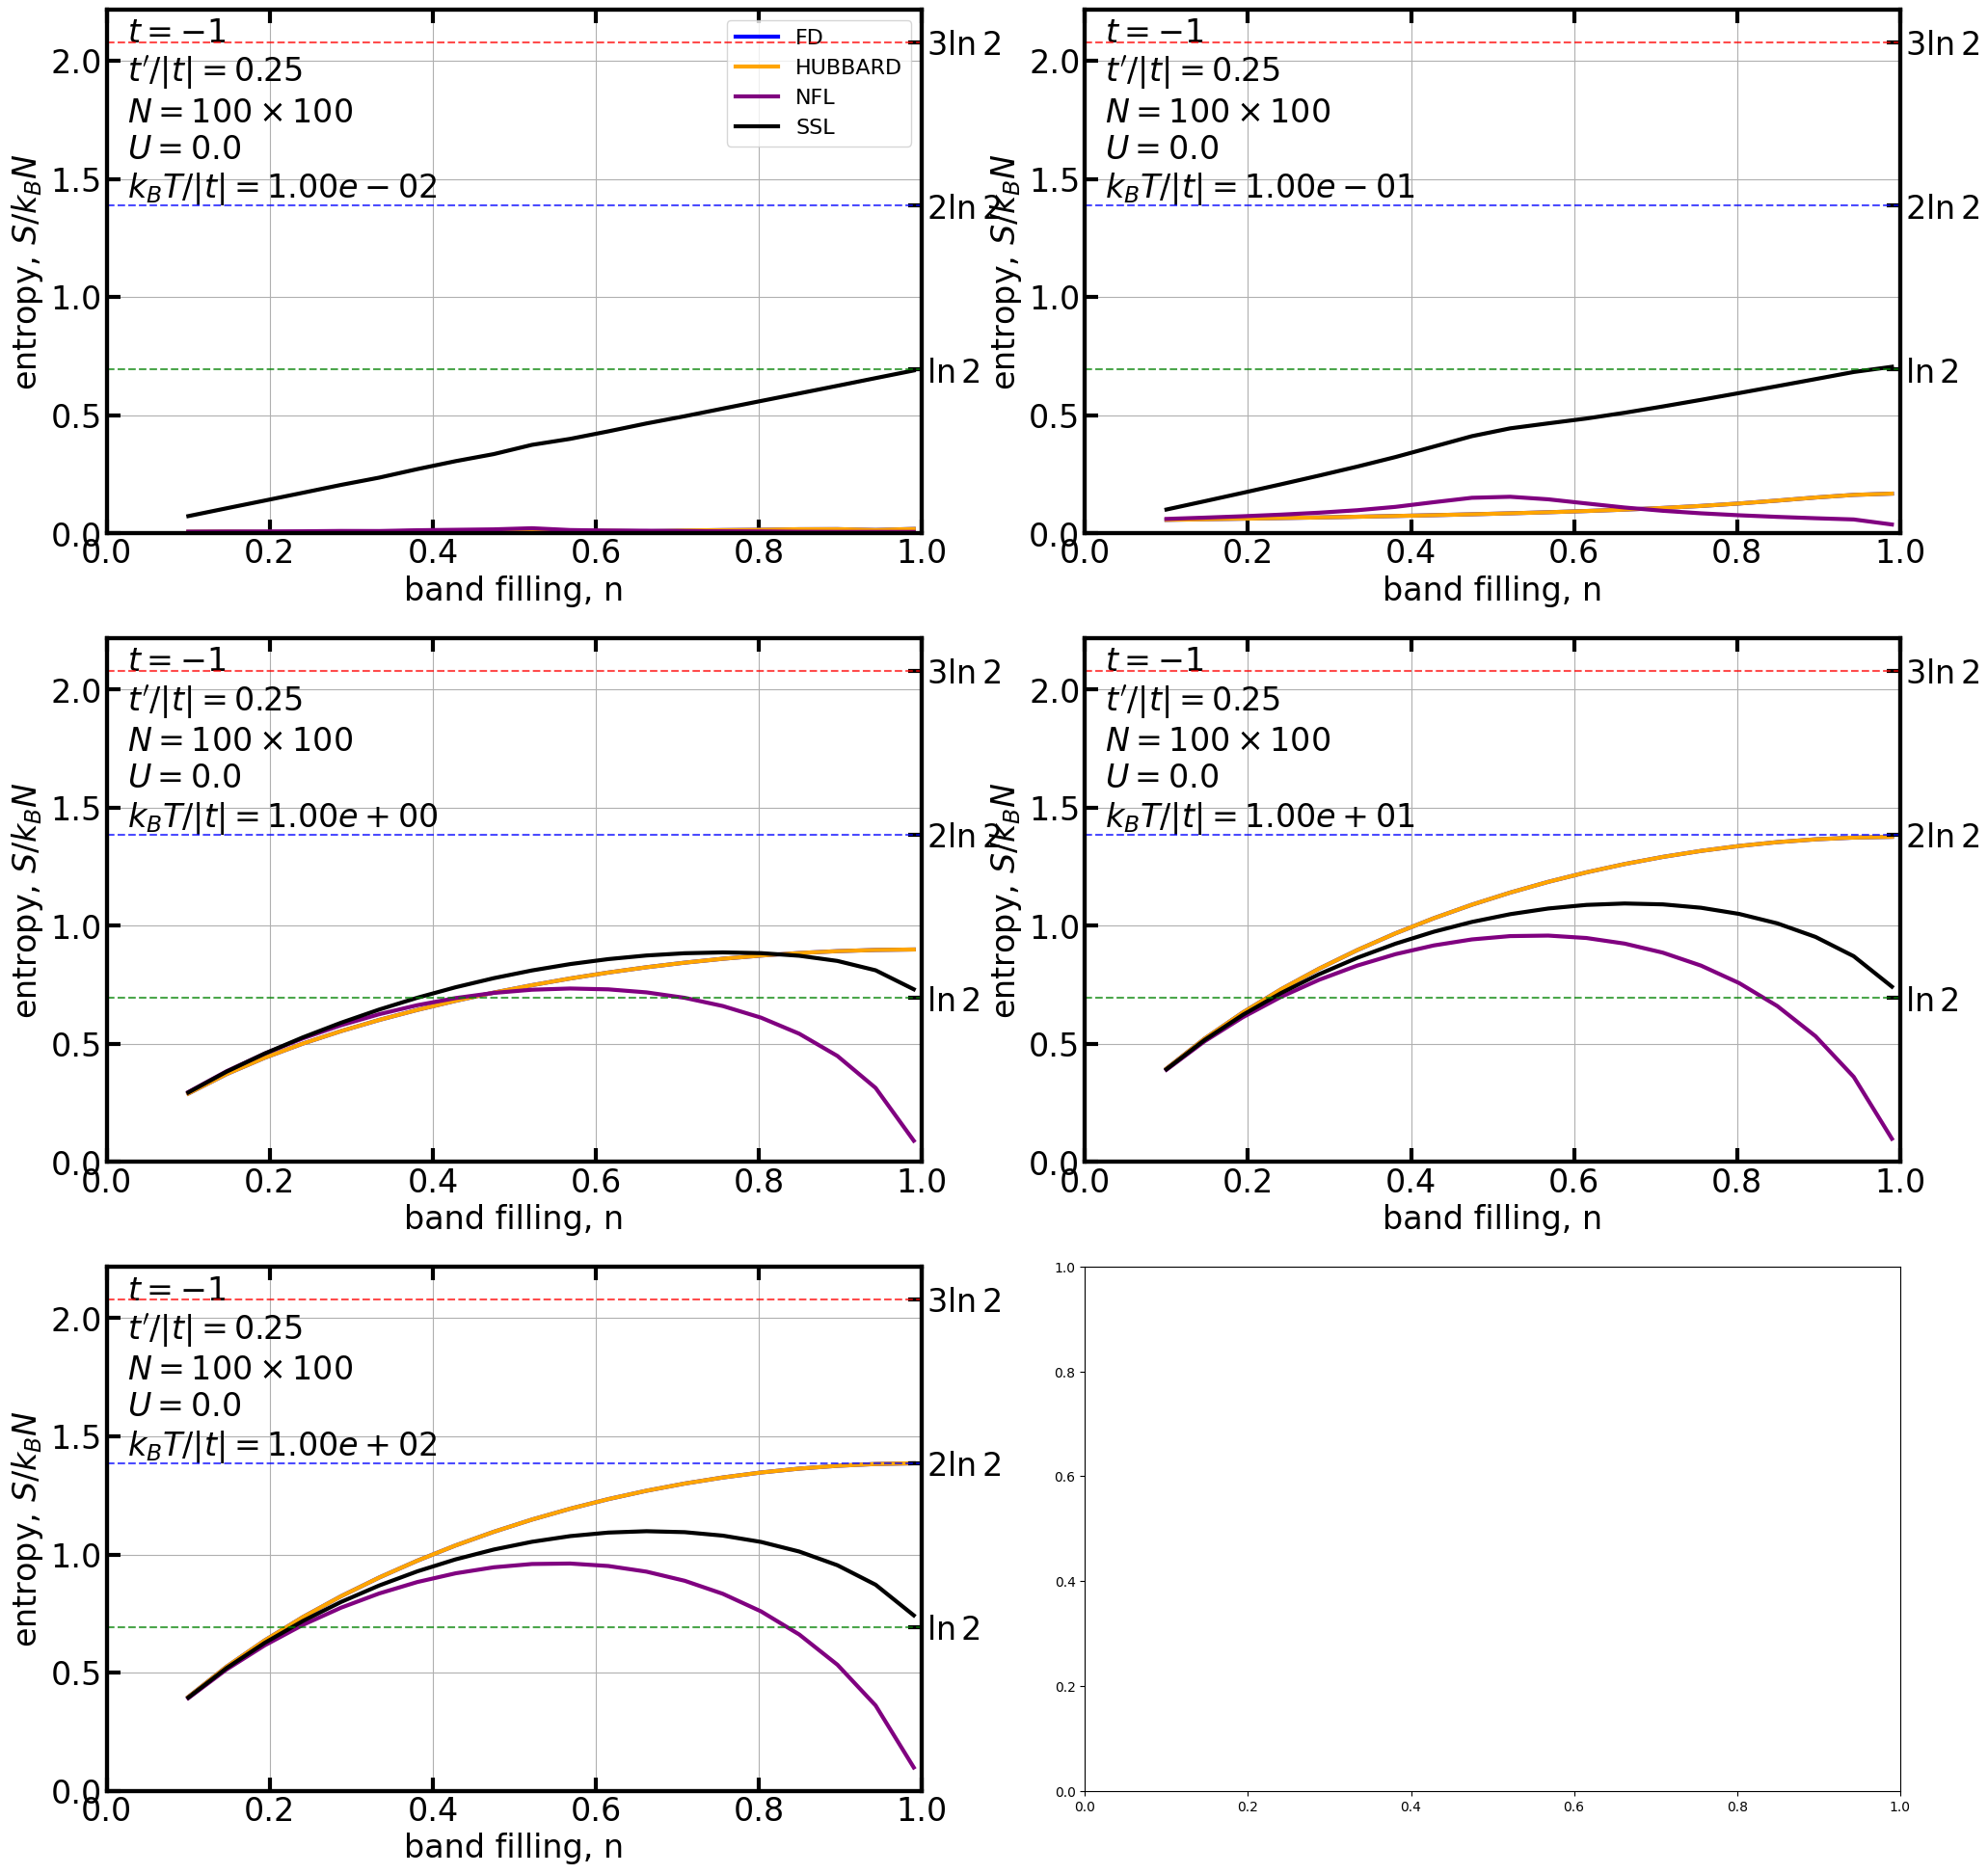

In [5]:
H_a_plot = H_a[0] 
kBT_plot = kBT

# Plot
plotter.plot_scalar_result(
    results=entropy_df,
    x_param="n",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=list(distro),
    subplots_param="kBT",
    subplots_vals=kBT_plot,
    cols=2,
    figsize=(12, 8),
    show_log_vals=True,
    ylims=(0, 2.5),
    xlims=(0, 1)
)
plt.show()

### $\frac{S} {k_B N} = f(k_BT)$


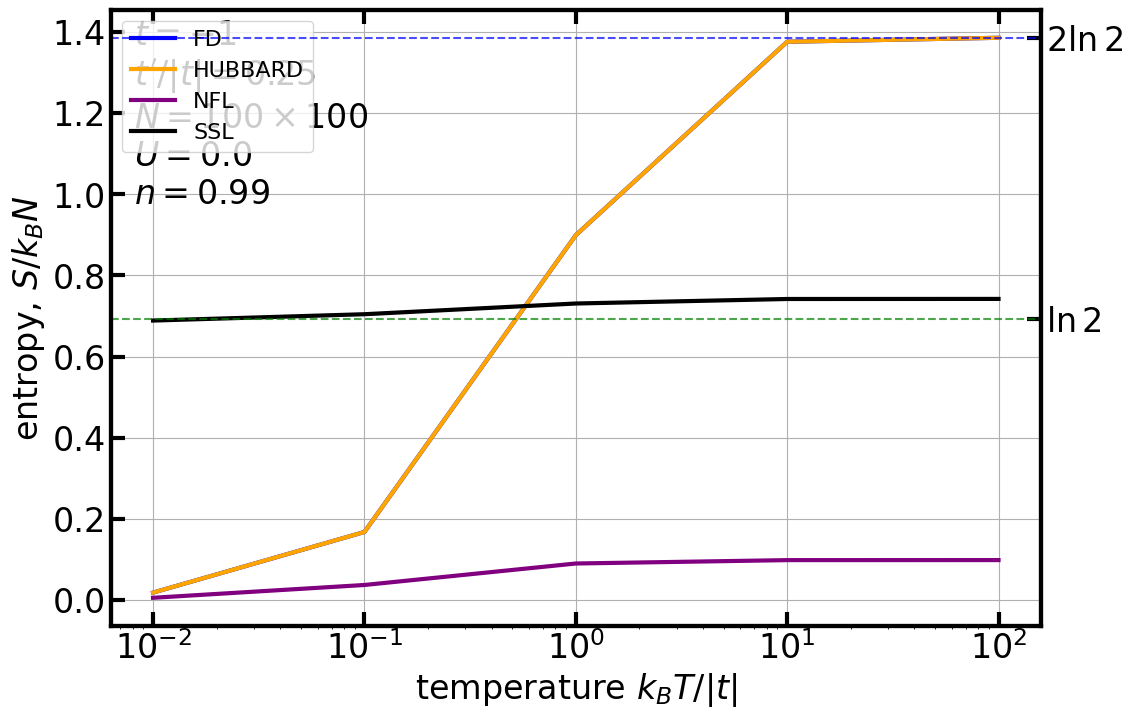

In [6]:
n_plot = [n[-1]]
H_a_plot = H_a[0]

# Plot
plotter.plot_scalar_result(
    results=entropy_df,
    x_param="k_BT",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"H_a": H_a_plot},
    distros=list(distro),
    subplots_param="n",
    subplots_vals=n_plot,
    cols=1,
    show_log_vals=True,
    figsize=(12, 8),
    xscale="log"
)
plt.show()

#### $\frac{S} {k_B N} = f(H_a)$

/home/mateuszzx/Workspace/Programming_Workspace/Spalek_Workspace/quantum-statistics-solver/tools/scientific_plot_v2.py:95: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax.set_xscale(xscale)


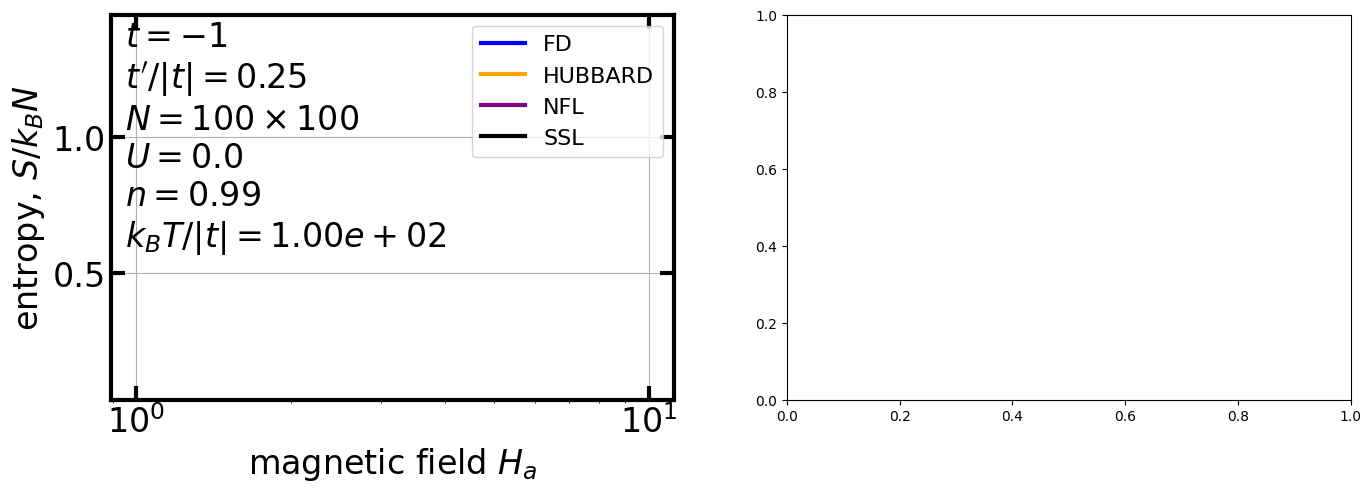

In [7]:
n_plot = [n[-1]]
kBT_plot = kBT[-1]
plotter.plot_scalar_result(
    results=entropy_df,
    x_param="H_a",
    y_col="entropy",
    y_label=r"entropy, $S / k_B N$",
    fixed_params={"kBT": kBT_plot},
    distros=list(distro),
    subplots_param="n",
    subplots_vals=n_plot,
    cols=2,
    figsize=(8, 5),
    xscale="log"
)
plt.show()

#### $\frac{S} {k_B N} = f(n, k_BT)$

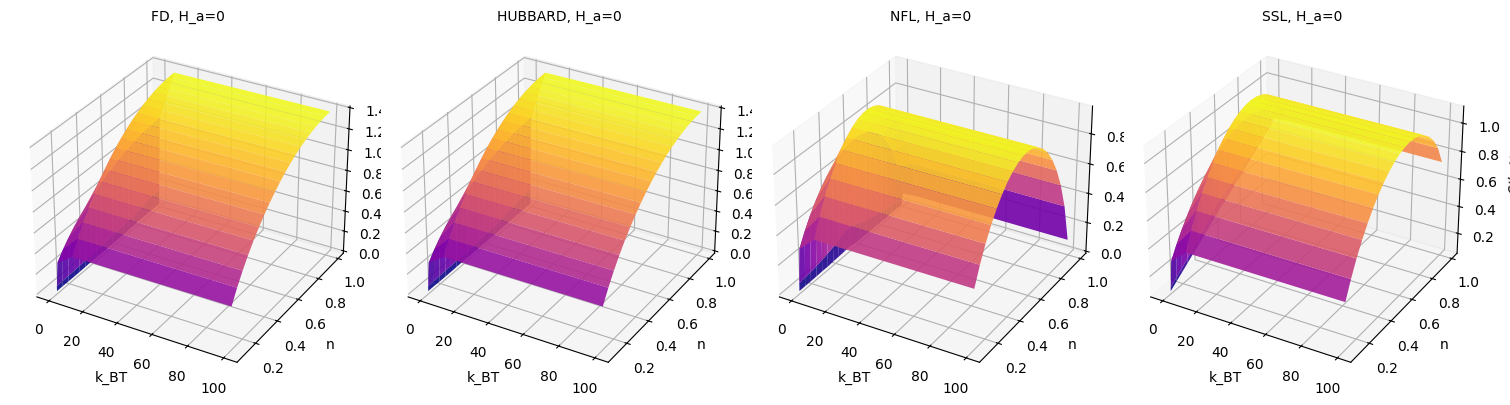

In [8]:
# Example: Plot Entropy vs Temperature (k_BT) and Magnetic Field (H_a)
# for different band fillings (n)

# Select a few n values for the rows
plotter.plot_3d_results(
    results=entropy_df,
    row_param="H_a",       # Vary n across rows
    row_vals=H_a,     # Specific n values
    x_param="k_BT",      # X axis
    y_param="n",       # Y axis
    z_label=r"$S / k_B N$",
    z_col="entropy",          # or "entropy" if you have calculated it
    distros=list(distro),
    # figsize=(15, 10)
)
plt.show()